# FraudGuard - Phase 2: Exploratory Data Analysis

**Dataset:** Kaggle *Credit Card Fraud Detection* (`mlg-ulb/creditcardfraud`),
read from `data/raw/creditcard.csv` (read-only; never modified).

**Scope of this notebook:** loading, data-quality checks, class imbalance,
`Amount`, `Time`, and correlation analysis only.

**Out of scope (later phases):** model training, resampling, `/predict`,
persistence. Nothing here fits a model or scores a transaction.

### What the columns are

| Column | Meaning |
| --- | --- |
| `Time` | Seconds elapsed since the **first record in the file**. Not a date, not a clock time. |
| `V1`-`V28` | Output of a PCA transformation applied by the dataset authors. |
| `Amount` | Transaction amount. |
| `Class` | Target: `0` = legitimate, `1` = fraudulent. |

The `V1`-`V28` names do **not** map to known financial variables. The dataset
authors withheld the original features for confidentiality, so no cell in this
notebook assigns them a business meaning. Treat them as opaque, already-scaled
numeric signals.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

TARGET = "Class"
LEGIT, FRAUD = 0, 1


def find_project_root() -> Path:
    """Walk up from the current directory until requirements.txt is found."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "requirements.txt").exists():
            return candidate
    raise RuntimeError("Could not locate the project root (requirements.txt).")


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "creditcard.csv"
print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)

Project root: D:\FraudGuard-Phase1
Dataset path: D:\FraudGuard-Phase1\data\raw\creditcard.csv


## 1. Load and verify the file

Verifying the load matters: a silent `read_csv` on the wrong file, a truncated
download, or a wrong delimiter all produce a DataFrame that *looks* fine until
much later.

In [2]:
if not DATA_PATH.exists():
    raise SystemExit(
        f"Dataset missing at {DATA_PATH}.\n"
        "Download 'creditcard.csv' from Kaggle and place it at data/raw/creditcard.csv"
    )

df = pd.read_csv(DATA_PATH)

assert not df.empty, "Dataset loaded but contains no rows."
expected = ["Time", *[f"V{i}" for i in range(1, 29)], "Amount", "Class"]
assert set(expected) == set(df.columns), "Unexpected columns"

print(f"Rows: {df.shape[0]:,}  Columns: {df.shape[1]}")
print(f"File size: {DATA_PATH.stat().st_size / 1024**2:.1f} MB")
df.head()

Rows: 284,807  Columns: 31
File size: 143.8 MB


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Structure, types, and descriptive statistics

Every column is numeric and fully populated. `Class` is the only integer column
and is really a boolean flag wearing a costume - something to fix in the feature
pipeline later, not here.

In [3]:
dtype_table = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "nulls": df.isna().sum(),
        "n_unique": df.nunique(),
    }
)
dtype_table

,dtype,non_null,nulls,n_unique
Time,float64,284807,0,124592
V1,float64,284807,0,275663
V2,float64,284807,0,275663
V3,float64,284807,0,275663
V4,float64,284807,0,275663
V5,float64,284807,0,275663
V6,float64,284807,0,275663
V7,float64,284807,0,275663
V8,float64,284807,0,275663
V9,float64,284807,0,275663


In [4]:
df[["Time", "Amount", TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16
Class,284807.0,0.001727,0.041527,0.0,0.0,0.0,0.000,1.00


`Time` has a mean of roughly 94,800 s and spans 0 to 172,792 s. `Amount` is
extremely right-skewed: its mean (88.35) is four times its median (22.00), which
is the classic signature of a heavy tail.

The PCA features are already centred around 0 with unit-ish variance - the
authors standardised before publishing, so no scaling is strictly required for
linear models, though it does no harm.

In [5]:
df.describe().T.loc[[f"V{i}" for i in range(1, 29)]].head(10)

,count,mean,std,min,25%,50%,75%,max
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995
V10,284807.0,2.236957e-15,1.088850,-24.588262,-0.535426,-0.092917,0.453923,23.745136


## 3. Data quality: missing values and duplicates

Both checks are cheap and both matter. Missing values silently break scikit-learn
estimators; duplicates inflate apparent sample size and can leak across a
train/test split if the same row lands in both sides.

In [6]:
total_nulls = int(df.isna().sum().sum())
duplicates = int(df.duplicated().sum())

print(f"Missing cells:      {total_nulls:,}")
print(f"Duplicate rows:     {duplicates:,}  ({duplicates / len(df) * 100:.3f}% of the data)")
print(f"Rows after dropping: {len(df) - duplicates:,}")

Missing cells:      0
Duplicate rows:     1,081  (0.380% of the data)
Rows after dropping: 283,726


There are **no missing values** - every one of the 284,807 x 31 cells is
populated.

There are **1,081 exact duplicate rows** (0.380%). They are reported here and
deliberately **not dropped**. Reasoning: these columns are PCA components, which
compress many underlying variables into 28 numbers. Two genuinely distinct
transactions that happen to share identical `Time`, `Amount` and all 28
components are unlikely but not impossible, and a duplicate-looking row is
harmless to keep while dropping a real one is not. The decision belongs to the
modelling phase, where the train/test split has to be designed so duplicates
cannot span both sides (group-aware splitting or dedupe before splitting).

## 4. Class imbalance

This is the single most important fact about the dataset, and it dictates every
modelling choice in later phases.

In [7]:
counts = df[TARGET].value_counts().sort_index()
legit_count = int(counts[LEGIT])
fraud_count = int(counts[FRAUD])
total = len(df)

summary = pd.DataFrame(
    {
        "class": ["legitimate (0)", "fraudulent (1)"],
        "count": [legit_count, fraud_count],
        "percentage": [legit_count / total * 100, fraud_count / total * 100],
    }
).round(4)

print(summary.to_string(index=False))
print()
print(f"Fraud-to-legitimate ratio: 1 : {legit_count / fraud_count:.0f}")
summary

         class  count  percentage
legitimate (0) 284315     99.8273
fraudulent (1)    492      0.1727

Fraud-to-legitimate ratio: 1 : 578


,class,count,percentage
0,legitimate (0),284315,99.8273
1,fraudulent (1),492,0.1727


In [8]:
baseline_accuracy = legit_count / total * 100
print(f"Hypothetical 'predict legitimate always' accuracy: {baseline_accuracy:.3f}%")
print(f"Its fraud recall: 0.000%  (it never predicts fraud)")
print(f"It would miss all {fraud_count:,} fraudulent transactions.")

Hypothetical 'predict legitimate always' accuracy: 99.827%
Its fraud recall: 0.000%  (it never predicts fraud)
It would miss all 492 fraudulent transactions.


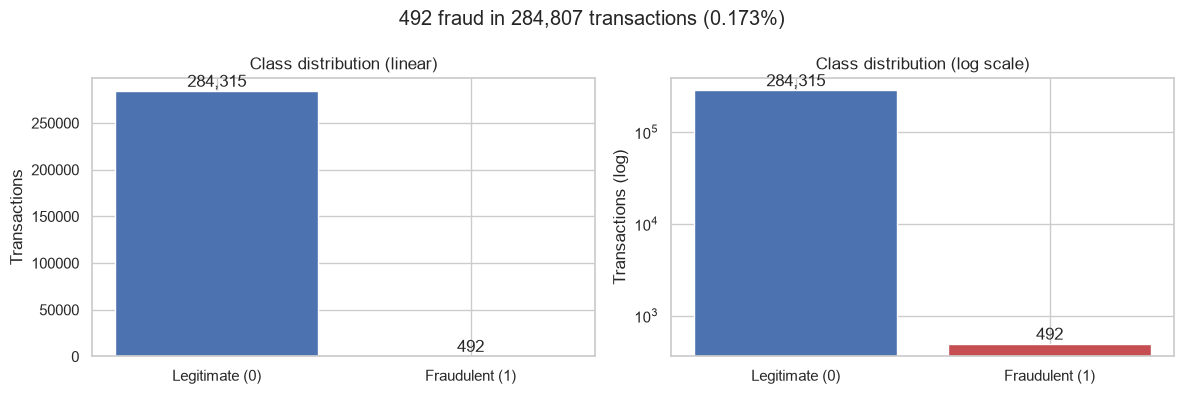

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels, values, colors = ["Legitimate (0)", "Fraudulent (1)"], [legit_count, fraud_count], ["#4C72B0", "#C44E52"]

bars = axes[0].bar(labels, values, color=colors)
axes[0].set_title("Class distribution (linear)")
axes[0].set_ylabel("Transactions")
for bar, value in zip(bars, values):
    axes[0].annotate(f"{value:,}", (bar.get_x() + bar.get_width() / 2, value),
                     xytext=(0, 3), textcoords="offset points", ha="center")

bars = axes[1].bar(labels, values, color=colors)
axes[1].set_yscale("log")
axes[1].set_title("Class distribution (log scale)")
axes[1].set_ylabel("Transactions (log)")
for bar, value in zip(bars, values):
    axes[1].annotate(f"{value:,}", (bar.get_x() + bar.get_width() / 2, value),
                     xytext=(0, 3), textcoords="offset points", ha="center")
fig.suptitle(f"{fraud_count:,} fraud in {total:,} transactions ({fraud_count / total * 100:.3f}%)")
fig.tight_layout()
plt.show()

### Why accuracy is the wrong metric here

Accuracy is `correct predictions / all predictions`. With 99.827% of rows being
legitimate, a model that outputs "legitimate" and nothing else scores **99.827%
accuracy while catching exactly zero fraud**. The number looks excellent and the
system is worthless.

The failure is structural, not a quirk of one bad model: accuracy weights every
row equally, and legitimate rows outnumber fraud rows 578 to 1. Any metric that
treats classes symmetrically is dominated by the majority class.

What to report instead, in later phases:

- **Precision** - of the transactions flagged as fraud, how many were fraud?
  Directly controls how many customers get wrongly blocked.
- **Recall** - of the actual frauds, how many did we catch? This is the loss
  function of the business.
- **F1 / PR-AUC** - single numbers that trade those two off. **PR-AUC is far
  more informative than ROC-AUC** under this much imbalance, because ROC-AUC is
  flattered by the enormous number of true negatives.
- **A confusion matrix with raw counts** - always, so the 492 frauds stay
  visible.

And a practical point: because there are only 492 frauds, the test set will
contain only ~98 of them at a 20% split. A single extra false negative moves
recall by about one percentage point, so metrics will be noisy and should be
reported with cross-validated ranges rather than a single number.

## 5. Transaction `Amount`

`Amount` is the only column with an interpretable business scale, so it is worth
describing carefully - especially because its distribution is pathological for
mean-based summaries.

In [10]:
def amount_stats(series: pd.Series) -> dict[str, float]:
    return {
        "count": series.count(),
        "mean": series.mean(),
        "median": series.median(),
        "std": series.std(),
        "min": series.min(),
        "q25": series.quantile(0.25),
        "q75": series.quantile(0.75),
        "max": series.max(),
        "skew": series.skew(),
    }


amount_table = pd.DataFrame(
    {
        "all": amount_stats(df["Amount"]),
        "legitimate": amount_stats(df.loc[df[TARGET] == LEGIT, "Amount"]),
        "fraudulent": amount_stats(df.loc[df[TARGET] == FRAUD, "Amount"]),
    }
).round(4)
amount_table

,all,legitimate,fraudulent
count,284807.0000,284315.0000,492.0000
mean,88.3496,88.2910,122.2113
median,22.0000,22.0000,9.2500
std,250.1201,250.1051,256.6833
min,0.0000,0.0000,0.0000
q25,5.6000,5.6500,1.0000
q75,77.1650,77.0500,105.8900
max,25691.1600,25691.1600,2125.8700
skew,16.9777,17.0031,3.7545


Reading the table:

- **Mean 88.35 vs median 22.00.** The mean is dragged up by a small number of
  very large transactions; the median describes the typical transaction.
- **Standard deviation 250 is larger than the mean**, another symptom of the
  same heavy tail - the standard deviation is not a useful spread measure here.
- **Maximum 25,691.16** vs **75th percentile 77.17**: half of all transactions
  are under 22, yet the largest is a thousand times that.
- **Fraudulent transactions have a lower median (9.25) but a higher mean
  (122.21).** Frauds cluster at small amounts with a subset of large ones. The
  two distributions overlap heavily, so `Amount` alone cannot separate classes -
  it is one weak feature among many.

There are also **1,825 zero-amount transactions** (0.641%). A $0 transaction is
not necessarily bad data - it can be an authorisation check or a reversed
transaction - but it deserves handling in the feature pipeline rather than being
silently dropped.

In [11]:
zero_amount = int((df["Amount"] == 0).sum())
print(f"Zero-amount transactions: {zero_amount:,} ({zero_amount / len(df) * 100:.3f}%)")

q1, q3 = df["Amount"].quantile([0.25, 0.75])
iqr = q3 - q1
fence = q3 + 1.5 * iqr
print(f"IQR upper fence: {fence:.2f}")

for label, mask in (("legitimate", df[TARGET] == LEGIT), ("fraudulent", df[TARGET] == FRAUD)):
    series = df.loc[mask, "Amount"]
    above = int((series > fence).sum())
    print(f"{label:>11}: {above:,} above fence ({above / len(series) * 100:.3f}% of class)")

Zero-amount transactions: 1,825 (0.641%)
IQR upper fence: 184.51
 legitimate: 31,813 above fence (11.189% of class)
 fraudulent: 91 above fence (18.496% of class)


**Outliers are reported, not removed.** A large amount is a genuine fraud signal,
so deleting high-value rows would delete the signal. Robust modelling choices
later: a log transform of `Amount`, tree models that do not care about scale, or
quantile-based capping - all of which keep the rows.

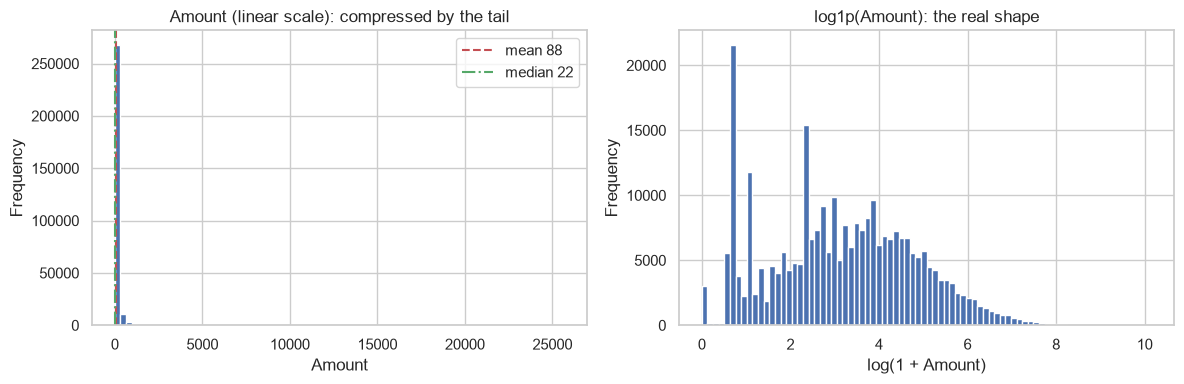

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["Amount"], bins=80, color="#4C72B0")
axes[0].axvline(df["Amount"].mean(), color="#C44E52", linestyle="--", label=f"mean {df['Amount'].mean():.0f}")
axes[0].axvline(df["Amount"].median(), color="#55A868", linestyle="-.", label=f"median {df['Amount'].median():.0f}")
axes[0].set_title("Amount (linear scale): compressed by the tail")
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Frequency")
axes[0].legend()

axes[1].hist(np.log1p(df["Amount"]), bins=80, color="#4C72B0")
axes[1].set_title("log1p(Amount): the real shape")
axes[1].set_xlabel("log(1 + Amount)")
axes[1].set_ylabel("Frequency")
fig.tight_layout()
plt.show()

The linear histogram is nearly useless - almost every bar is squeezed into the
first few dollars. `log1p` (log(1+x), which is safe for zeros, unlike plain log)
reveals the true shape: a broad multi-modal distribution. This is the standard
diagnostic that tells you to log-transform a skewed amount feature.

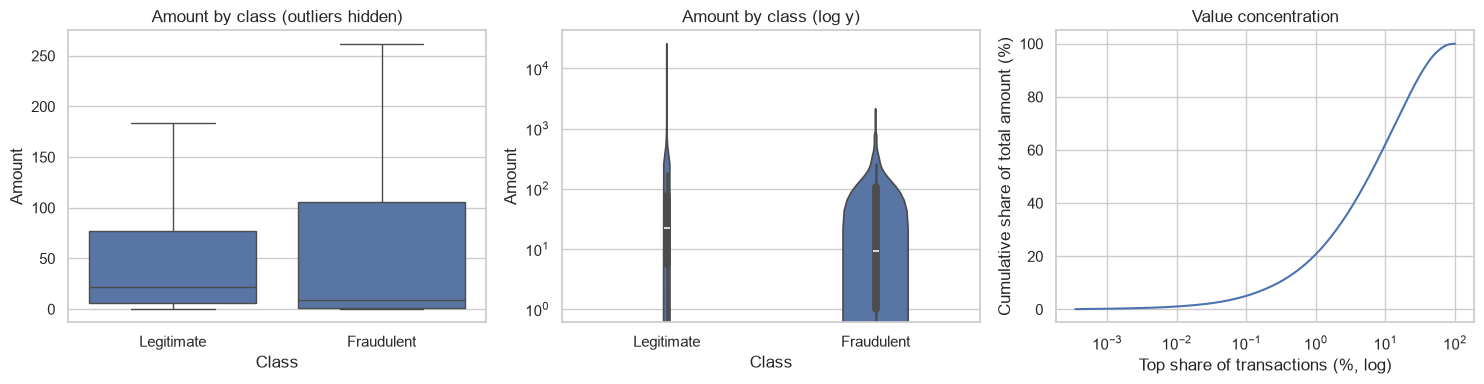

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(data=df, x=TARGET, y="Amount", ax=axes[0], showfliers=False)
axes[0].set_title("Amount by class (outliers hidden)")
axes[0].set_xticks([0, 1], ["Legitimate", "Fraudulent"])

sns.violinplot(data=df, x=TARGET, y="Amount", ax=axes[1], cut=0)
axes[1].set_yscale("log")
axes[1].set_title("Amount by class (log y)")
axes[1].set_xticks([0, 1], ["Legitimate", "Fraudulent"])

descending = np.sort(df["Amount"].to_numpy())[::-1]
cumulative = np.cumsum(descending) / descending.sum() * 100
share = np.arange(1, len(descending) + 1) / len(descending) * 100
axes[2].plot(share, cumulative, color="#4C72B0")
axes[2].set_xscale("log")
axes[2].set_title("Value concentration")
axes[2].set_xlabel("Top share of transactions (%, log)")
axes[2].set_ylabel("Cumulative share of total amount (%)")

fig.tight_layout()
plt.show()

## 6. Transaction `Time`

`Time` is **elapsed seconds since the first row**, not a timestamp. The dataset
carries no calendar date, no weekday, no real hour-of-day. Any "hour" below is an
offset within the recording window.

Spanning 0 to 172,792 s means the file covers **48 hours of continuous
recording**, which is almost certainly two consecutive real days - but the
dataset does not tell us which, so we never pretend it does.

In [14]:
span_seconds = df["Time"].max() - df["Time"].min()
print(f"Time range: {df['Time'].min():,.0f} to {df['Time'].max():,.0f} seconds")
print(f"Span: {span_seconds / 3600:.2f} hours ({span_seconds / 86400:.2f} days)")

Time range: 0 to 172,792 seconds
Span: 48.00 hours (2.00 days)


In [15]:
hourly = (
    df.assign(elapsed_hour=(df["Time"] // 3600).astype(int))
      .groupby("elapsed_hour")[TARGET]
      .agg(transactions="size", fraudulent="sum")
      .reset_index()
)
hourly["legitimate"] = hourly["transactions"] - hourly["fraudulent"]
hourly["fraud_rate_pct"] = (hourly["fraudulent"] / hourly["transactions"] * 100).round(4)

print(f"Busiest hour:  {int(hourly.loc[hourly['transactions'].idxmax(), 'elapsed_hour'])} "
      f"({hourly['transactions'].max():,} transactions)")
print(f"Peak fraud count in one hour: {int(hourly['fraudulent'].max())} "
      f"(hour {int(hourly.loc[hourly['fraudulent'].idxmax(), 'elapsed_hour'])})")
print(f"Highest hourly fraud rate: {hourly['fraud_rate_pct'].max():.3f}% "
      f"(hour {int(hourly.loc[hourly['fraud_rate_pct'].idxmax(), 'elapsed_hour'])})")
print(f"Hours with zero fraud: {int((hourly['fraudulent'] == 0).sum())} of {len(hourly)}")
hourly.head()

Busiest hour:  21 (9,895 transactions)
Peak fraud count in one hour: 43 (hour 11)
Highest hourly fraud rate: 2.055% (hour 26)
Hours with zero fraud: 2 of 48


,elapsed_hour,transactions,fraudulent,legitimate,fraud_rate_pct
0,0,3963,2,3961,0.0505
1,1,2217,2,2215,0.0902
2,2,1576,21,1555,1.3325
3,3,1821,13,1808,0.7139
4,4,1082,6,1076,0.5545


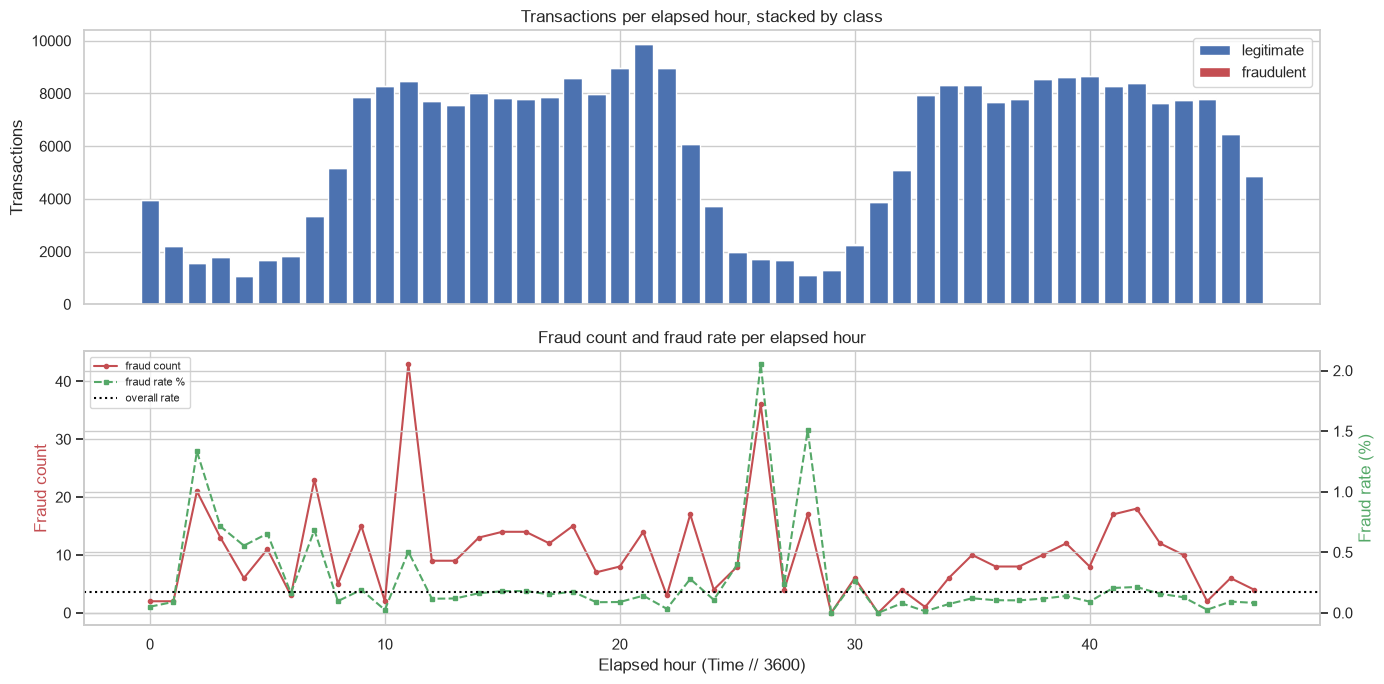

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].bar(hourly["elapsed_hour"], hourly["legitimate"], color="#4C72B0", label="legitimate")
axes[0].bar(hourly["elapsed_hour"], hourly["fraudulent"], bottom=hourly["legitimate"],
            color="#C44E52", label="fraudulent")
axes[0].set_title("Transactions per elapsed hour, stacked by class")
axes[0].set_ylabel("Transactions")
axes[0].legend()

axes[1].plot(hourly["elapsed_hour"], hourly["fraudulent"], color="#C44E52", marker="o", markersize=3, label="fraud count")
axes[1].set_title("Fraud count and fraud rate per elapsed hour")
axes[1].set_xlabel("Elapsed hour (Time // 3600)")
axes[1].set_ylabel("Fraud count", color="#C44E52")
twin = axes[1].twinx()
twin.plot(hourly["elapsed_hour"], hourly["fraud_rate_pct"], color="#55A868", marker="s",
          markersize=3, linestyle="--", label="fraud rate %")
twin.axhline(df[TARGET].mean() * 100, color="black", linestyle=":", label="overall rate")
twin.set_ylabel("Fraud rate (%)", color="#55A868")
lines = axes[1].get_lines() + twin.get_lines()
axes[1].legend(lines, [line.get_label() for line in lines], fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

What the time view shows:

- **Traffic is not uniform.** Volume drops to roughly 1,000-2,000 transactions in
  the quiet hours and peaks near 9,895. The dip-and-rise pattern recurs roughly
  every 24 hours, which is consistent with day/night behaviour - but since
  `Time` has no date, this is an inference about *elapsed offsets*, not a proven
  clock-time effect.
- **Fraud counts do not follow volume.** Fraud is spread across the whole window
  and occasionally spikes in hours that are not the busiest, so "more traffic"
  and "more fraud" are not the same curve.
- **Hourly fraud rate is extremely noisy.** The highest rate (2.055%) comes from
  an hour with only 1,752 transactions and 36 frauds. Two hours contain **zero**
  fraud. With only 492 frauds spread over 48 buckets, roughly 10 per hour, a
  1-fraud difference moves the rate a lot. Do not read a "peak" hour here as a
  real behavioural pattern.

One thing this analysis *does* justify for later: if you ever split this data
randomly, neighbouring minutes of the same event can land in both train and test.
That is a leakage risk, covered below.

## 7. Correlation analysis

A correlation matrix answers exactly one narrow question: how strong is the
*linear* relationship between each pair of columns. It is a starting point, not a
feature-selection verdict.

In [17]:
corr = df.corr(numeric_only=True)
with_class = corr[TARGET].drop(TARGET).sort_values(key=lambda s: s.abs(), ascending=False)

pd.DataFrame({"correlation": with_class.round(4), "abs": with_class.abs().round(4)}).head(12)

,correlation,abs
V17,-0.3265,0.3265
V14,-0.3025,0.3025
V12,-0.2606,0.2606
V10,-0.2169,0.2169
V16,-0.1965,0.1965
V3,-0.1930,0.1930
V7,-0.1873,0.1873
V11,0.1549,0.1549
V4,0.1334,0.1334
V18,-0.1115,0.1115


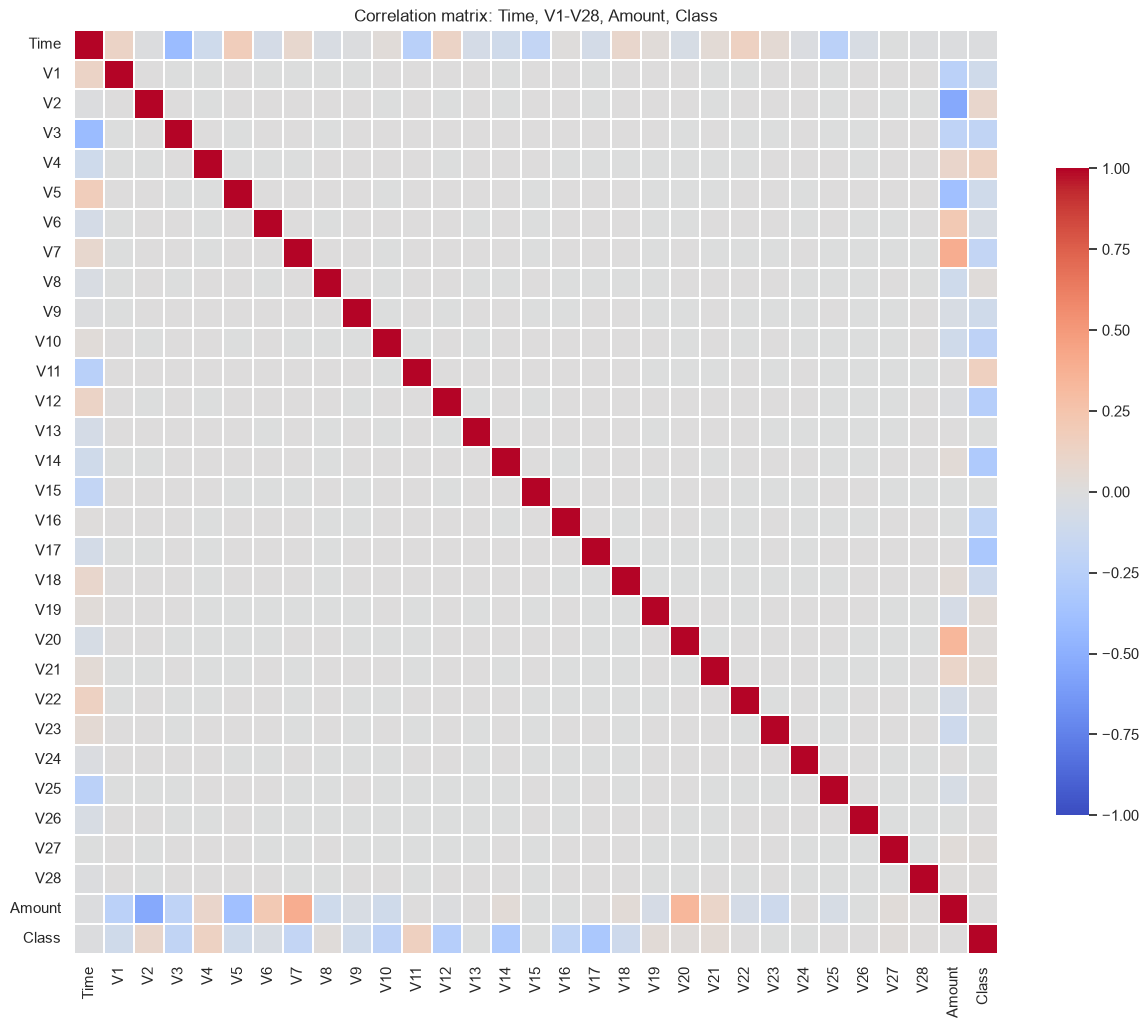

In [18]:
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.2, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlation matrix: Time, V1-V28, Amount, Class")
plt.show()

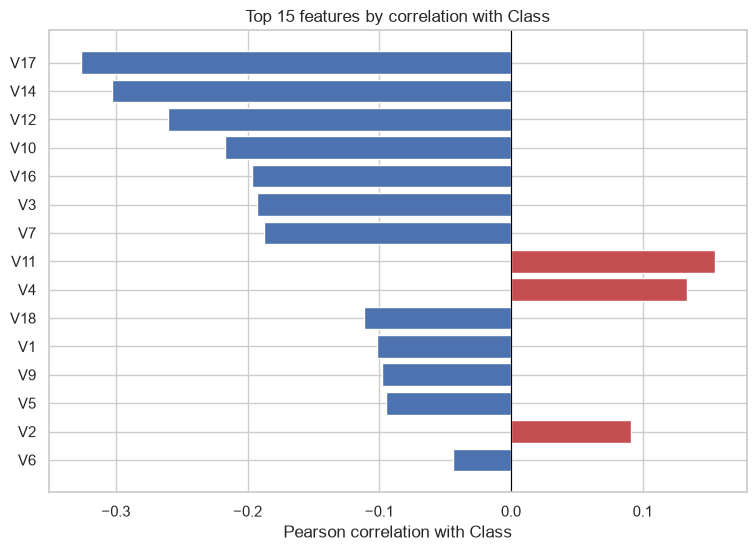

In [19]:
top = with_class.head(15).iloc[::-1]
colors = ["#C44E52" if v > 0 else "#4C72B0" for v in top]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Top 15 features by correlation with Class")
ax.set_xlabel("Pearson correlation with Class")
plt.show()

In [20]:
print("Strongest linear associations with Class:")
print(with_class.head(5).round(4).to_string())
print()
print(f"Largest |r| with Class: {with_class.abs().max():.4f} ({with_class.abs().idxmax()})")
print(f"Weakest:                {with_class.abs().min():.4f} ({with_class.abs().idxmin()})")
print()
print(f"r(Amount, V2) = {df['Amount'].corr(df['V2']):+.4f}")
print(f"r(Time, V3)   = {df['Time'].corr(df['V3']):+.4f}")
print(f"r(Time, Amount) = {df['Time'].corr(df['Amount']):+.4f}")

Strongest linear associations with Class:
V17   -0.3265
V14   -0.3025
V12   -0.2606
V10   -0.2169
V16   -0.1965

Largest |r| with Class: 0.3265 (V17)
Weakest:                0.0008 (V22)

r(Amount, V2) = -0.5314
r(Time, V3)   = -0.4196
r(Time, Amount) = -0.0106


### How to read this

- **`V17`, `V14`, `V12`, `V10` carry the strongest linear signal** against
  `Class` (roughly -0.33 to -0.22). The sign is arbitrary: it comes from the sign
  the PCA rotation happened to give each component. Only the magnitude matters.
- **Nothing exceeds |r| = 0.33.** No single feature separates fraud. This is the
  central modelling lesson of Phase 2: fraud here is a **multivariate, weakly
  signalled** pattern, which is exactly why a linear threshold on one column will
  fail and why ensembles and interaction-aware models earn their keep later.
- **`Time` alone is nearly useless** (`r(Time, Amount) = -0.01`), and `V22` has
  essentially zero correlation with `Class`.
- **`Amount` correlates meaningfully with `V2` (-0.53), `V7` (+0.40),
  `V5` (-0.39), `V20` (+0.34).** These are not errors - they reflect structure
  the PCA components retain about amount. Worth knowing because it means `Amount`
  is partially redundant with some components.
- **`r(Time, V3) = -0.42`** is real and verified independently. It is an artifact
  of how the components were derived over this recording window, and it is a good
  reminder that "PCA components are uncorrelated" applies to the original
  *input* features, not to a subset re-measured in a filtered dataset.

### Why correlation alone does not establish predictive usefulness

1. **Correlation is linear only.** A feature that is powerfully predictive
   through a threshold or an interaction (fraud only when `V4` is high *and*
   `Amount` is small) can show `r = 0` and still be valuable. Tree models exploit
   exactly that.
2. **Correlation is computed on a 578:1 class imbalance.** `r` is a
   variance-weighted, whole-sample statistic, so it is dominated by the legitimate
   rows. A feature that distinguishes fraud well within the tiny fraud cluster can
   produce a small `r`.
3. **Correlation is marginal, not conditional.** It ignores what *other* features
   already explain. Two features can each look weak alone and be strong together;
   or one can look strong only because it duplicates another.
4. **Correlation says nothing about direction of causality** (and here there is
   none to find).
5. **`r` is computed on the data you have.** Features that look weak on this
   sample may matter on another population; the target population may have a
   different fraud mix entirely.

Use correlation to spot **obvious redundancy and obvious leakage**, then let
cross-validated model performance decide usefulness.

### Why `V1`-`V28` cannot be read as financial variables

The dataset authors applied PCA and withheld the original features for
confidentiality. Each `V` column is a **linear combination of several underlying,
unknown variables**, so:

- A high `V14` does not mean "high risk score", "large foreign transfer", or
  anything else nameable. Any such statement would be invented.
- The sign has no business meaning; `-0.30` is not "less fraudulent" in any
  interpretable sense.
- Individual model coefficients on `V` features are **not explainable to a
  customer or a regulator** - which matters for a fraud product, where a declined
  payment often must be justified. Flagging this now shapes the next phase:
  explainability will need post-hoc methods (e.g. SHAP on feature groups) or
  surrogate features, not coefficient reading.
- Any feature engineering on `V` columns (ratios, products) creates quantities
  with no defensible interpretation either.

## 8. Data leakage - the risk that will decide Phase 3

**Data leakage** is any information reaching the model during training that would
not be available at prediction time, or that has already seen the test data. It
produces beautiful validation scores and a model that fails in production. With
this dataset there are four concrete traps:

1. **Fitting transforms on the full dataset.** If you compute the scaler,
   log-transform statistics, or imputation values on all 284,807 rows *before*
   splitting, the training data has already absorbed test-set information. Fit on
   train, then `transform` test.
2. **Resampling before splitting.** If you apply SMOTE/undersampling to the whole
   dataset and then split, synthetic fraud points are built from test frauds and
   copies of the same fraud land on both sides. Split first; resample only the
   training fold (and ideally inside the CV loop, not before it).
3. **Duplicate rows spanning the split.** Those 1,081 exact duplicates are why
   the split must be **group-aware**: dedupe before splitting, or group identical
   rows so a duplicate cannot appear in both train and test.
4. **Temporal leakage.** The records are ordered in time over 48 hours. A random
   split lets the model learn from the future and be tested on the past. For a
   real-time service the honest evaluation is a **time-based split**: train on the
   earlier window, test on the later one.

Why it matters *now*, in Phase 2: the EDA decisions (which transforms, whether to
dedupe, how to resample, how to split) are exactly where leakage is introduced.
Nothing in this notebook fits a model, so no leakage has occurred yet - but every
choice above constrains Phase 3.

## 9. Key findings

All figures below come from this run on `data/raw/creditcard.csv`.

**Data quality**
- 284,807 rows x 31 columns, 143.8 MB, **no missing values**.
- **1,081 exact duplicate rows (0.380%)** - reported, not dropped.
- Every column is numeric; `Class` is the only integer column.

**Class imbalance**
- Legitimate: **284,315 (99.8273%)**. Fraudulent: **492 (0.1727%)**.
- Ratio **1 fraud : 578 legitimate**.
- A "predict legitimate always" dummy would score **99.827% accuracy with 0%
  fraud recall** - the reason accuracy is unusable here.

**Amount**
- Overall: mean **88.35**, median **22.00**, std **250.12**, min **0.00**,
  max **25,691.16**, skew **16.98**.
- Legitimate: median **22.00**, mean **88.29**. Fraudulent: median **9.25**, mean
  **122.21** - frauds skew small but have a heavier mean.
- **1,825 zero-amount transactions (0.641%)**.
- Value is concentrated: the **top 0.1%** of transactions by amount hold **5.1%** of total value, the **top 1%** hold **20.8%**, the **top 10%** hold **62.2%**.
- IQR upper fence **184.51**: **11.189%** of legitimate and **18.496%** of fraud
  rows sit above it. Kept, not removed.

**Time**
- Range **0 to 172,792 s** = **48.00 hours** (~2 days) of continuous recording.
  No calendar date exists in the data.
- Busiest elapsed hour: **hour 21 with 9,895 transactions**.
- Peak fraud in one hour: **43** (hour 11). Highest hourly rate **2.055%** (hour
  26, 36 of 1,752) - a noisy small-denominator figure.
- **2 of 48 hours contain zero fraud.**

**Correlation**
- Strongest with `Class`: **V17 -0.3265**, V14 -0.3025, V12 -0.2606, V10 -0.2169.
- **No feature exceeds |r| = 0.3265**; `V22` is effectively zero (+0.0008).
- `Amount` vs `V2` **-0.5314**, vs `V7` **+0.3973**; `Time` vs `V3` **-0.4196**;
  `Time` vs `Amount` **-0.0106**.

**Conclusions that constrain Phase 3**
1. Accuracy, ROC-AUC alone, and "predict always legitimate" are all off the table.
   Report precision/recall/F1/PR-AUC with confusion matrices.
2. No single feature works. Expect to need non-linear, interaction-aware models
   (logistic regression as a baseline is still worth having, but low correlation
   does not mean low coefficient value).
3. Design the split before anything else: group-aware dedupe plus a time-based
   holdout. Apply resampling only inside the training fold.
4. Keep outliers and zero amounts; transform `Amount` (log) rather than delete
   rows.
5. `V1`-`V28` are uninterpretable - plan post-hoc explainability instead of
   reading coefficients.

**Not done here:** no model was trained, no resampling was applied, no endpoint
was added, and the raw CSV was never modified.